# Batch processing of GRS L2A images with GRSl2bgen

This notebook processes a time series of GRS Level-2A products (one site or tile)
into GRSl2bgen Level-2B water quality products:

1. **Configuration**: input/output folders, site, date range, output format.
2. **List the L2A products** found on disk and select a date range.
3. **Output naming**: one L2B product per L2A product, in a `YYYY/MM/DD` tree.
4. **Run the batch**: products already processed are skipped, a failing product
   is logged and does not stop the batch, and a summary table is saved.
5. **Quick look** at one L2B product.

For very long batches (hundreds of full Sentinel-2 tiles), the command line is
more robust than a notebook: each product runs in its own Python process, so
memory is fully released between products (see the last section).

```{note}
The outputs shown here come from a run on the 732 Sentinel-2 subsets (2017-2024) of
the HYPERNETS site `BEFR` (tile 31TFJ): 348 products had been processed by a
previous, interrupted run and were skipped, the 384 others took about 9 s each.
The notebook is not re-executed when the documentation is built (the data are not
available there); the processing log of the batch cell is shortened.
```


In [1]:
import os
import glob
import time
import shutil
import logging
import warnings
import contextlib
import datetime as dt

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

import GRSl2bgen

opj = os.path.join

# INFO messages of the processing chain; set to logging.WARNING for a quieter batch
logging.getLogger().setLevel(logging.INFO)
# GRS L2A files are stored with chunks that do not match the processing chunks:
# harmless for the results, so the performance hint is silenced
warnings.filterwarnings('ignore', message='The specified chunks separate the stored chunks')

print(f'GRSl2bgen: {GRSl2bgen.__version__}')

GRSl2bgen: 1.0.2


## 1. Configuration

The L2A products are expected in a `<rootdir>/<site>/YYYY/MM/DD/<product>` tree,
where `<product>` is a GRS L2A `.nc` file, a `.zarr` store, or a directory holding
`<product>.nc` and its `<product>_anc.nc` ancillary file. The L2B products are
written to the same tree under `<odir>/<site>`.

| Parameter | Description |
|---|---|
| `rootdir`, `odir` | root folders of the L2A inputs and of the L2B outputs |
| `site` | site or tile sub-folder (e.g. `BEFR`, `31TFJ`) |
| `pattern` | glob pattern of the L2A product names |
| `start_date`, `end_date` | date range to process (inclusive) |
| `out_ext` | `'.nc'` (NetCDF) or `'.zarr'` (Zarr store) |
| `pyramid` | for `.zarr`: write a multiscale (pyramid) store for cloud visualisation |
| `overwrite` | reprocess products whose L2B output already exists |
| `n_workers` | `None`: dask threaded scheduler; an integer: one local dask cluster with this many worker processes, shared by the whole batch |
| `persist_input` | keep each masked L2A raster in memory (faster, needs more RAM) |

In [2]:
rootdir = '/data/satellite/Sentinel-2/subset/hypernets/L2A_v221'
odir = '/data/satellite/Sentinel-2/subset/hypernets/L2B_v221'
site = 'BEFR'

# other examples:
# rootdir, odir, site = '/data/satellite/Sentinel-2/L2A', '/data/satellite/Sentinel-2/L2B', '30TWR'
# rootdir, odir, site = '/data/satellite/Sentinel-2/subset/L2A', '/data/satellite/Sentinel-2/subset/L2B', 'parentis'

pattern = '*L2A*'
start_date, end_date = '2016-01-01', '2026-12-31'

out_ext = '.nc'        # '.nc' or '.zarr'
pyramid = False        # only for '.zarr'
overwrite = False

n_workers = None       # e.g. 4
persist_input = False

## 2. List the L2A products

The product names follow the Sentinel-2 convention, optionally followed by the GRS
version:

`<satellite>_<level>_<sensing time>_<baseline>_<orbit>_<tile>_<processing time>[_<version>]`

e.g. `S2B_MSIL2A_20170418T104019_N0500_R008_T31TFJ_20231114T053559` or
`S2B_MSIL2A_20200411T110619_N0500_R137_T30TWR_20230509T002033_V2.2.1`. The products
are indexed by sensing time, so that a date range can be selected with `.loc`.

In [3]:
FIELDS = ['satellite', 'level', 'time', 'baseline', 'orbit', 'tile', 'processing_time', 'version']


def product_name(path):
    """Product name without folder and extension."""
    name = os.path.basename(path.rstrip('/'))
    for ext in ('.nc', '.zarr'):
        if name.endswith(ext):
            name = name[:-len(ext)]
    return name


def list_products(rootdir, site, pattern='*L2A*'):
    """Table of the L2A products found in <rootdir>/<site>/YYYY/MM/DD/, indexed by sensing time."""
    paths = sorted(glob.glob(opj(rootdir, site, '*', '*', '*', pattern)))
    rows = []
    for path in paths:
        fields = product_name(path).split('_')
        if len(fields) < 7:
            logging.warning(f'unexpected product name, skipped: {path}')
            continue
        # the version field is optional
        fields = (fields + [None])[:len(FIELDS)]
        rows.append(dict(zip(FIELDS, fields), path=path))
    df = pd.DataFrame(rows, columns=FIELDS + ['path'])
    df['time'] = pd.to_datetime(df['time'], format='%Y%m%dT%H%M%S')
    return df.set_index('time').sort_index()


products = list_products(rootdir, site, pattern)
print(f'{len(products)} L2A products found in {opj(rootdir, site)}')
products.head()

732 L2A products found in /data/satellite/Sentinel-2/subset/hypernets/L2A_v221/BEFR


,satellite,level,baseline,orbit,tile,processing_time,version,path
time,,,,,,,,
2017-01-03 10:44:32,S2A,MSIL2A,N0500,R008,T31TFJ,20230926T025711,None,/data/satellite/Sentinel-2/subset/hypernets/L2...
2017-01-13 10:44:01,S2A,MSIL2A,N0500,R008,T31TFJ,20231025T155034,None,/data/satellite/Sentinel-2/subset/hypernets/L2...
2017-02-02 10:42:41,S2A,MSIL2A,N0500,R008,T31TFJ,20231025T004856,None,/data/satellite/Sentinel-2/subset/hypernets/L2...
2017-02-19 10:30:51,S2A,MSIL2A,N0500,R108,T31TFJ,20231025T084923,None,/data/satellite/Sentinel-2/subset/hypernets/L2...
2017-02-22 10:40:31,S2A,MSIL2A,N0500,R008,T31TFJ,20231026T035832,None,/data/satellite/Sentinel-2/subset/hypernets/L2...


In [4]:
selection = products.loc[start_date:end_date]
print(f'{len(selection)} products between {start_date} and {end_date}')
selection.groupby(selection.index.year).size().rename('products per year').to_frame().T

732 products between 2016-01-01 and 2026-12-31


time,2017,2018,2019,2020,2021,2022,2023,2024
products per year,87,91,94,90,89,90,96,95


## 3. Output naming

Each L2B product keeps the name of its L2A product, with `L2A` replaced by `L2B`, and
is written to `<odir>/<site>/YYYY/MM/DD/`.

In [5]:
def l2b_path(l2a_path, sensing_time):
    name = product_name(l2a_path).replace('L2A', 'L2B').replace('L1C', 'L2B')
    return opj(odir, site, sensing_time.strftime('%Y/%m/%d'), name + out_ext)


selection = selection.assign(l2b=[l2b_path(p, t) for t, p in selection['path'].items()])
selection['done'] = selection['l2b'].map(os.path.exists)
print(f"{selection['done'].sum()} already processed, {(~selection['done']).sum()} to process")
selection[['path', 'l2b', 'done']].head()

348 already processed, 384 to process


,path,l2b,done
time,,,
2017-01-03 10:44:32,/data/satellite/Sentinel-2/subset/hypernets/L2...,/data/satellite/Sentinel-2/subset/hypernets/L2...,True
2017-01-13 10:44:01,/data/satellite/Sentinel-2/subset/hypernets/L2...,/data/satellite/Sentinel-2/subset/hypernets/L2...,True
2017-02-02 10:42:41,/data/satellite/Sentinel-2/subset/hypernets/L2...,/data/satellite/Sentinel-2/subset/hypernets/L2...,True
2017-02-19 10:30:51,/data/satellite/Sentinel-2/subset/hypernets/L2...,/data/satellite/Sentinel-2/subset/hypernets/L2...,True
2017-02-22 10:40:31,/data/satellite/Sentinel-2/subset/hypernets/L2...,/data/satellite/Sentinel-2/subset/hypernets/L2...,True


## 4. Run the batch

For each product:

- it is **skipped** if its L2B output already exists (unless `overwrite=True`), so the
  batch can be interrupted and restarted at any time;
- `Process.run` executes the processing chain, writes the output and closes the
  input files;
- if the processing **fails**, the error is logged, the partially written output (if any) is
  removed so that the product is retried at the next run, and the batch goes on.

With `n_workers` set, a single local dask cluster is started for the whole batch
(instead of one per product) and closed at the end.

In [6]:
def remove_output(path):
    if os.path.isdir(path):
        shutil.rmtree(path)
    elif os.path.isfile(path):
        os.remove(path)


def process_product(l2a, l2b):
    """Process one product; return (status, duration in s, error message)."""
    if os.path.exists(l2b):
        if not overwrite:
            return 'skipped', 0., ''
        remove_output(l2b)
    os.makedirs(os.path.dirname(l2b), exist_ok=True)
    t0 = time.perf_counter()
    try:
        process = GRSl2bgen.Process(l2a, l2b, pyramid=pyramid, persist_input=persist_input)
        process.run()
        del process
        return 'done', time.perf_counter() - t0, ''
    except Exception as e:
        logging.exception(f'processing failed: {l2a}')
        remove_output(l2b)
        return 'failed', time.perf_counter() - t0, f'{type(e).__name__}: {e}'


if n_workers:
    from dask.distributed import Client
    # the client owns the cluster: both are closed at the end of the with block
    scheduler = Client(n_workers=n_workers, threads_per_worker=1)
    print(f'dask dashboard: {scheduler.dashboard_link}')
else:
    scheduler = contextlib.nullcontext()

records = []
with scheduler:
    for i, (sensing_time, row) in enumerate(selection.iterrows(), start=1):
        status, duration, error = process_product(row['path'], row['l2b'])
        records.append(dict(time=sensing_time, status=status, duration_s=round(duration, 1),
                            error=error, l2a=row['path'], l2b=row['l2b']))
        if status != 'skipped':
            print(f'[{i}/{len(selection)}] {status:6s} {os.path.basename(row["l2b"])} ({duration:.1f} s)')

summary = pd.DataFrame(records, columns=['time', 'status', 'duration_s', 'error', 'l2a', 'l2b'])
summary['status'].value_counts()

[349/732] done   S2A_MSIL2B_20201031T103201_N0500_R108_T31TFJ_20230314T200914.nc (11.3 s)
[350/732] done   S2B_MSIL2B_20201105T103229_N0500_R108_T31TFJ_20230302T024503.nc (10.0 s)
[351/732] done   S2B_MSIL2B_20201108T104249_N0500_R008_T31TFJ_20230302T080018.nc (9.1 s)
... (378 more products) ...
[730/732] done   S2B_MSIL2B_20241224T103349_N0511_R108_T31TFJ_20241224T122441.nc (9.7 s)
[731/732] done   S2B_MSIL2B_20241227T104349_N0511_R008_T31TFJ_20241227T123454.nc (9.8 s)
[732/732] done   S2A_MSIL2B_20241229T103441_N0511_R108_T31TFJ_20241229T123148.nc (9.8 s)


status
done       384
skipped    348
Name: count, dtype: int64

The summary is saved as a CSV file next to the L2B products. Failed products can be
inspected below and reprocessed by running the batch again.

In [7]:
if len(summary):
    log_file = opj(odir, site, f'batch_{dt.datetime.now():%Y%m%dT%H%M%S}.csv')
    os.makedirs(os.path.dirname(log_file), exist_ok=True)
    summary.to_csv(log_file, index=False)
    print(f'summary saved to {log_file}')
    processed = summary[summary.status == 'done']
    if len(processed):
        print(f'mean processing time: {processed.duration_s.mean():.1f} s per product')

summary[summary.status == 'failed'][['time', 'error', 'l2a']]

summary saved to /data/satellite/Sentinel-2/subset/hypernets/L2B_v221/BEFR/batch_20261013T211007.csv
mean processing time: 9.1 s per product


,time,error,l2a


## 5. Quick look at one L2B product

The last product of the selection is displayed. A pyramid Zarr store holds one
group per resolution level: group `0` is the full resolution.

In [8]:
l2b_file = selection['l2b'].iloc[-1]
group = '0' if (out_ext == '.zarr' and pyramid) else None
if l2b_file.endswith('.zarr'):
    l2b = xr.open_zarr(l2b_file, group=group, decode_coords='all')
else:
    l2b = xr.open_dataset(l2b_file, decode_coords='all')
l2b

<xarray.Dataset> Size: 264MB
Dimensions:                 (Nclasses: 3, y: 1280, x: 1280)
Coordinates:
  * Nclasses                (Nclasses) int64 24B 0 1 2
  * y                       (y) float64 10kB 4.828e+06 4.828e+06 ... 4.802e+06
  * x                       (x) float64 10kB 6.57e+05 6.571e+05 ... 6.826e+05
    time                    datetime64[ns] 8B ...
    band                    int64 8B ...
    spatial_ref             int64 8B ...
    central_wavelength      float32 4B ...
Data variables: (12/17)
    owt_dist_Spyrakos2018   (Nclasses, y, x) float64 39MB ...
    owt_index_Spyrakos2018  (Nclasses, y, x) float64 39MB ...
    owt_dist_Bi2024         (y, x) float64 13MB ...
    owt_index_Bi2024        (y, x) float64 13MB ...
    owt_dist_Ta2025         (y, x) float64 13MB ...
    owt_index_Ta2025        (y, x) float64 13MB ...
    ...                      ...
    TURB_dogliotti          (y, x) float64 13MB ...
    SPM_nechad              (y, x) float64 13MB ...
    acdom_B15               (y, x) float64 13MB ...
    Kd_par                  (y, x) float64 13MB ...
    flags                   (y, x) int64 13MB ...
    mask                    (y, x) uint8 2MB ...
Attributes: (12/73)
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/31TFJ...
    product_name:                        S2A_MSIL1C_20241229T103441_N0511_R10...
    product_filename:                    S2A_MSIL1C_20241229T103441_N0511_R10...
    ...                                  ...
    vis_swir_index_threshold:            0.0
    hcld_threshold:                      0.003
    dirdata:                             /data/grs/grsdata
    abs_gas_file:                        /home/harmel/Dropbox/Dropbox/work/gi...
    water_vapor_transmittance_file:      /home/harmel/Dropbox/Dropbox/work/gi...
    metadata_profile:                    datacube

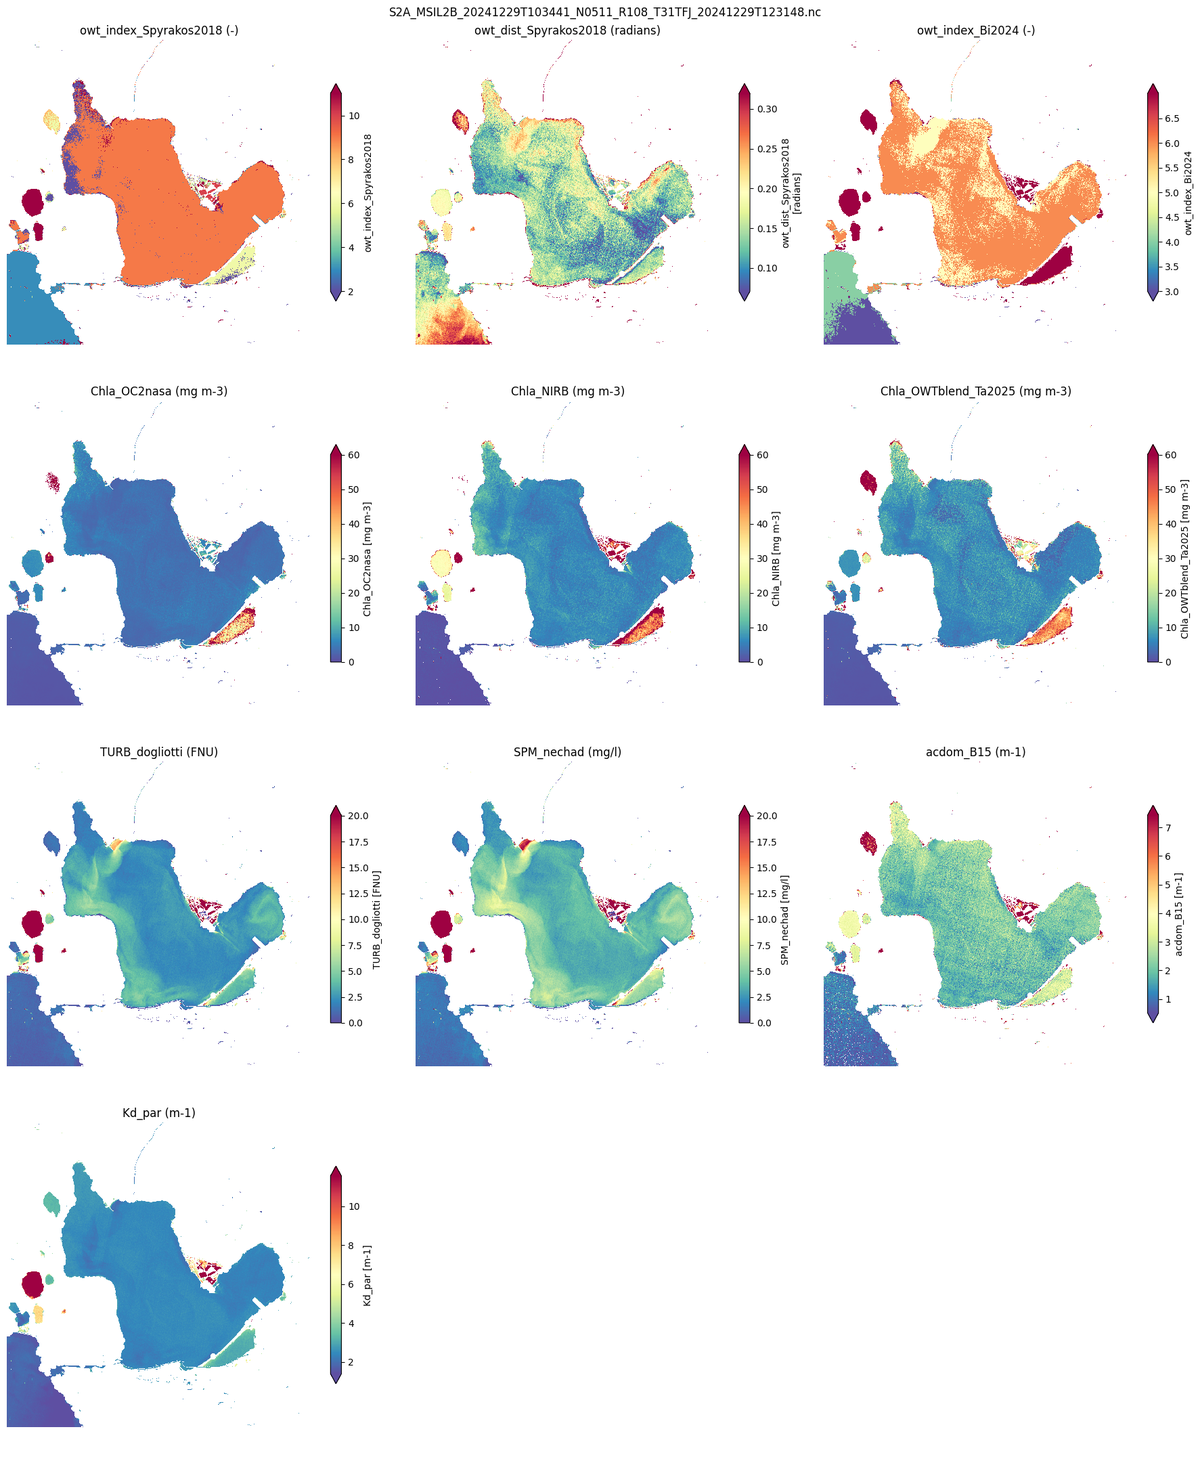

In [9]:
params = ['owt_index_Spyrakos2018', 'owt_dist_Spyrakos2018', 'owt_index_Bi2024',
          'Chla_OC2nasa', 'Chla_NIRB', 'Chla_OWTblend_Ta2025',
          'TURB_dogliotti', 'SPM_nechad', 'acdom_B15', 'Kd_par']
params = [p for p in params if p in l2b]
vmax = {'Chl': 60, 'TURB': 20, 'SPM': 20}   # colour scale upper limits by parameter family

# UTM projection from the EPSG code (326zz: north, 327zz: south)
epsg = l2b.rio.crs.to_epsg()
proj = ccrs.UTM(epsg % 100, southern_hemisphere=(epsg // 100 == 327))

ncols = 3
nrows = int(np.ceil(len(params) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5.5 * nrows),
                        subplot_kw={'projection': proj})
for ax in axs.ravel():
    ax.set_axis_off()
for ax, param in zip(axs.ravel(), params):
    da = l2b[param]
    if 'Nclasses' in da.dims:          # 3 best Spyrakos classes: show the first one
        da = da.isel(Nclasses=0)
    family = next((k for k in vmax if param.startswith(k)), None)
    kwargs = dict(vmin=0, vmax=vmax[family]) if family else {}
    da.squeeze().plot.imshow(ax=ax, cmap=plt.cm.Spectral_r, robust=True,
                             cbar_kwargs={'shrink': 0.6}, **kwargs)
    ax.set_title(f"{param} ({da.attrs.get('units', '-')})")
fig.suptitle(os.path.basename(l2b_file))
plt.tight_layout()

## Alternative: batch from the command line

For long batches, run one `GRSl2bgen` process per product from a shell script:
memory is fully released after each product, and products can be processed in
parallel with `xargs -P`. `--no_clobber` skips the products already processed.

```bash
rootdir=/data/satellite/Sentinel-2/subset/hypernets/L2A_v221
odir=/data/satellite/Sentinel-2/subset/hypernets/L2B_v221
site=BEFR

process_one() {
    name=$(basename "${1%.nc}")
    t=$(echo "$name" | cut -d_ -f3)                  # sensing time, e.g. 20170418T104019
    out="$odir/$site/${t:0:4}/${t:4:2}/${t:6:2}/${name/L2A/L2B}.nc"
    GRSl2bgen "$1" -o "$out" --no_clobber || echo "FAILED $1" >> "$odir/$site/failed.txt"
}
export -f process_one; export odir site

# 4 products in parallel
find "$rootdir/$site" -mindepth 4 -maxdepth 4 -name '*L2A*' | sort | xargs -P 4 -I{} bash -c 'process_one {}'
```